# Phase 4 - Transferencia a Otra Divisa con Embedding + Clustering

Objetivo: usar la IA que armamos (encoder con atencion + clustering) para una nueva divisa Forex.

Pipeline:
1. Tomar otra divisa desde `phase1` (H1 dataset).
2. Extraer segmentos automaticamente en un rango temporal.
3. Entrenar encoder de referencia en `USDJPY` (misma arquitectura de Phase 3 v2).
4. Generar embeddings y clusters de referencia.
5. Proyectar segmentos de la nueva divisa al espacio embedding.
6. Asignar clusters y seleccionar segmentos informativos (menor intervencion humana).


In [1]:
import math
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 260)
pd.set_option('display.width', 320)


In [2]:
# =========================
# Config
# =========================
# Nueva divisa para transfer learning
SYMBOL_TARGET = 'EURUSD'
DATE_START = pd.Timestamp('2017-01-01 00:00:00')
DATE_END = pd.Timestamp('2019-12-31 23:59:59')

DATA_H1_DIR = Path('./data/Dataset_H1_v1/parquet_h1')
TARGET_PRICE_PATH = DATA_H1_DIR / f'{SYMBOL_TARGET}.parquet'

# Referencia USDJPY ya extraida en phase3
REF_CATALOG_PATH = Path('./phases/phase03_segment_analysis/output_extraccion/USDJPY_segments_extracted_catalog.parquet')
REF_LONG_PATH = Path('./phases/phase03_segment_analysis/output_extraccion/USDJPY_segments_extracted_long.parquet')
REF_SPLIT_PATH = Path('./phases/phase03_segment_analysis/output_extraccion/USDJPY_segments_split_temporal.parquet')
REF_PRICE_PATH = DATA_H1_DIR / 'USDJPY.parquet'

OUTPUT_DIR = Path(f'./phases/phase04_transfer_clustering/output_transfer_{SYMBOL_TARGET}')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_CATALOG_PARQUET = OUTPUT_DIR / f'{SYMBOL_TARGET}_segments_catalog.parquet'
TARGET_CATALOG_CSV = OUTPUT_DIR / f'{SYMBOL_TARGET}_segments_catalog.csv'
TARGET_LONG_PARQUET = OUTPUT_DIR / f'{SYMBOL_TARGET}_segments_long.parquet'
TARGET_LONG_CSV = OUTPUT_DIR / f'{SYMBOL_TARGET}_segments_long.csv'

TARGET_ASSIGN_PARQUET = OUTPUT_DIR / f'{SYMBOL_TARGET}_segment_cluster_assignments.parquet'
TARGET_ASSIGN_CSV = OUTPUT_DIR / f'{SYMBOL_TARGET}_segment_cluster_assignments.csv'
TARGET_SELECTED_PARQUET = OUTPUT_DIR / f'{SYMBOL_TARGET}_selected_segments.parquet'
TARGET_SELECTED_CSV = OUTPUT_DIR / f'{SYMBOL_TARGET}_selected_segments.csv'

REF_CLUSTER_PROFILE_CSV = OUTPUT_DIR / 'reference_usdjpy_cluster_profile.csv'
TRAIN_HISTORY_CSV = OUTPUT_DIR / 'transfer_encoder_train_history.csv'
EMB_NPZ = OUTPUT_DIR / f'{SYMBOL_TARGET}_embeddings_transfer.npz'
MODEL_WEIGHTS = OUTPUT_DIR / 'transfer_attention_encoder.pt'

SEED = 42
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# Segmentacion automatica en divisa target
EVENT_Q = 0.985
EVENT_MAX_GAP = 10
SEG_PREPAD = 6
SEG_POSTPAD = 10
MIN_SEG_BARS = 6
MAX_SEG_BARS = 176
MAX_OVERLAP = 0.60

# Encoder/Embedding (igual estilo Phase3 v2)
MAX_LEN = 176
D_MODEL = 96
EMB_DIM = 48
N_HEAD = 4
N_LAYERS = 3
FF_DIM = 192
DROPOUT = 0.15

BATCH_SIZE = 64
EPOCHS = 60
LR = 8e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 15
NOISE_STD = 0.03
MASK_DROPOUT = 0.08

# Clustering y seleccion
K_CLUSTERS = 10
HORIZON_HOURS = 24
MIN_CLUSTER_N = 20
ABS_MEAN_RET_MIN = 10.0

print('SYMBOL_TARGET =', SYMBOL_TARGET)
print('TARGET_PRICE_PATH =', TARGET_PRICE_PATH)
print('DEVICE =', DEVICE)
print('OUTPUT_DIR =', OUTPUT_DIR)


SYMBOL_TARGET = EURUSD
TARGET_PRICE_PATH = ./data/Dataset_H1_v1/parquet_h1/EURUSD.parquet
DEVICE = cuda
OUTPUT_DIR = ./phases/phase04_transfer_clustering/output_transfer_EURUSD


In [3]:
# =========================
# Reproducibilidad
# =========================
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

try:
    torch.set_float32_matmul_precision('high')
except Exception:
    pass


In [4]:
# =========================
# Helpers
# =========================
def pip_size(symbol: str) -> float:
    return 0.01 if str(symbol).upper().endswith('JPY') else 0.0001


def robust_zscore(x: np.ndarray, eps: float = 1e-8) -> np.ndarray:
    x = np.asarray(x, dtype=float)
    med = np.nanmedian(x)
    mad = np.nanmedian(np.abs(x - med))
    if not np.isfinite(mad) or mad < eps:
        m = np.nanmean(x)
        s = np.nanstd(x)
        if not np.isfinite(s) or s < eps:
            return np.zeros_like(x, dtype=float)
        z = (x - m) / (s + eps)
    else:
        z = (x - med) / (1.4826 * mad + eps)
    return np.clip(z, -8.0, 8.0)


def zscore_safe(x: np.ndarray, eps: float = 1e-8) -> np.ndarray:
    x = np.asarray(x, dtype=float)
    m = np.nanmean(x)
    s = np.nanstd(x)
    if not np.isfinite(s) or s < eps:
        return np.zeros_like(x, dtype=np.float32)
    return ((x - m) / (s + eps)).astype(np.float32)


def overlap_ratio(a0: int, a1: int, b0: int, b1: int) -> float:
    inter = max(0, min(a1, b1) - max(a0, b0) + 1)
    la = max(1, a1 - a0 + 1)
    lb = max(1, b1 - b0 + 1)
    return inter / float(min(la, lb))


def nms_segments(df: pd.DataFrame, max_overlap: float = 0.6) -> pd.DataFrame:
    if df.empty:
        return df.copy()
    d = df.sort_values('score_event', ascending=False).reset_index(drop=True)
    keep = []
    for _, r in d.iterrows():
        s0, s1 = int(r['start_idx']), int(r['end_idx'])
        ok = True
        for k in keep:
            ov = overlap_ratio(s0, s1, int(k['start_idx']), int(k['end_idx']))
            if ov > max_overlap:
                ok = False
                break
        if ok:
            keep.append(r)
    out = pd.DataFrame(keep).sort_values('start_idx').reset_index(drop=True)
    return out


def preprocess_sequence(close_arr: np.ndarray) -> np.ndarray:
    return zscore_safe(close_arr)


def load_price(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f'No existe path: {path}')
    keep = ['timestamp', 'open', 'high', 'low', 'close']
    df = pd.read_parquet(path, columns=keep).copy()
    df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
    for c in ['open', 'high', 'low', 'close']:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    df = df.dropna(subset=['timestamp', 'close'])
    df = df.sort_values('timestamp').drop_duplicates('timestamp', keep='last').reset_index(drop=True)
    return df


def compute_forward_pips(df_price: pd.DataFrame, ts_vec: pd.Series, symbol: str, horizon_hours: int = 24) -> np.ndarray:
    idx = df_price['timestamp'].to_numpy(dtype='datetime64[ns]')
    close = df_price['close'].to_numpy(dtype=float)
    ts = pd.to_datetime(ts_vec, errors='coerce').to_numpy(dtype='datetime64[ns]')
    pos = np.searchsorted(idx, ts, side='left')

    out = np.full(len(ts), np.nan, dtype=float)
    pip = pip_size(symbol)
    for i in range(len(ts)):
        p0 = pos[i]
        p1 = p0 + int(horizon_hours)
        if p0 < 0 or p1 >= len(idx):
            continue
        if idx[p0] != ts[i]:
            continue
        out[i] = (close[p1] - close[p0]) / pip
    return out


In [5]:
# =========================
# 1) Cargar nueva divisa desde phase1
# =========================
if not TARGET_PRICE_PATH.exists():
    raise FileNotFoundError(
        f'No existe {TARGET_PRICE_PATH}.\n'
        'Genera el H1 con phase1 (build_h1_dataset.py) para este simbolo y vuelve a ejecutar.'
    )

PX_T = load_price(TARGET_PRICE_PATH)
PX_T = PX_T[(PX_T['timestamp'] >= DATE_START) & (PX_T['timestamp'] <= DATE_END)].copy().reset_index(drop=True)
PX_T['idx'] = np.arange(len(PX_T), dtype=int)

if PX_T.empty:
    raise RuntimeError('No hay datos target en el rango temporal configurado.')

print('TARGET rows =', len(PX_T))
print('TARGET range =', PX_T['timestamp'].min(), '->', PX_T['timestamp'].max())
display(PX_T.head(3))


TARGET rows = 18646
TARGET range = 2017-01-02 02:00:00 -> 2019-12-31 16:00:00


,timestamp,open,high,low,close,idx
0,2017-01-02 02:00:00,1.05155,1.05230,1.05124,1.05153,0
1,2017-01-02 03:00:00,1.05152,1.05180,1.04865,1.04888,1
2,2017-01-02 04:00:00,1.04889,1.04921,1.04764,1.04865,2


In [6]:
# =========================
# 2) Segmentacion automatica en target
# =========================
# Eventos por shock de retorno + expansion de rango
close = PX_T['close'].to_numpy(dtype=float)
ret1 = np.zeros(len(close), dtype=float)
if len(close) > 1:
    prev = np.clip(close[:-1], 1e-12, None)
    curr = np.clip(close[1:], 1e-12, None)
    ret1[1:] = np.log(curr / prev)

range12 = (PX_T['high'].rolling(12, min_periods=3).max() - PX_T['low'].rolling(12, min_periods=3).min()).to_numpy(dtype=float)
drange = np.zeros_like(range12)
drange[1:] = np.diff(range12)

z_ret = np.abs(robust_zscore(ret1))
z_rng = np.abs(robust_zscore(drange))
score = 0.7 * z_ret + 0.3 * z_rng

thr = float(np.nanquantile(score[np.isfinite(score)], EVENT_Q))
event_idx = np.where(score >= thr)[0]

print('event threshold =', round(thr, 4), '| events =', len(event_idx))

# Agrupar eventos cercanos
clusters = []
if len(event_idx) > 0:
    cur = [int(event_idx[0])]
    for i in event_idx[1:]:
        i = int(i)
        if i - cur[-1] <= EVENT_MAX_GAP:
            cur.append(i)
        else:
            clusters.append(cur)
            cur = [i]
    clusters.append(cur)

rows = []
for c in clusters:
    s = max(0, min(c) - SEG_PREPAD)
    e = min(len(PX_T) - 1, max(c) + SEG_POSTPAD)
    n = e - s + 1
    if n < MIN_SEG_BARS:
        continue
    if n > MAX_SEG_BARS:
        e = min(len(PX_T) - 1, s + MAX_SEG_BARS - 1)
        n = e - s + 1

    w = PX_T.iloc[s:e+1]
    ps = pip_size(SYMBOL_TARGET)
    move_pips = (float(w['close'].iloc[-1]) - float(w['close'].iloc[0])) / ps
    range_pips = (float(w['high'].max()) - float(w['low'].min())) / ps
    sc = float(np.nanmax(score[s:e+1]))

    rows.append({
        'symbol': SYMBOL_TARGET,
        'start_idx': int(s),
        'end_idx': int(e),
        'start_ts': pd.Timestamp(w['timestamp'].iloc[0]),
        'end_ts': pd.Timestamp(w['timestamp'].iloc[-1]),
        'n_bars': int(n),
        'move_pips': float(move_pips),
        'range_pips': float(range_pips),
        'score_event': sc,
        'source': 'phase4_auto_event_segmentation',
    })

SEG_T = pd.DataFrame(rows)
if SEG_T.empty:
    raise RuntimeError('No se generaron segmentos target con la configuracion actual.')

SEG_T = nms_segments(SEG_T, max_overlap=MAX_OVERLAP)
SEG_T['global_segment_id'] = [f'{SYMBOL_TARGET}_seg_{i:05d}' for i in range(len(SEG_T))]
SEG_T = SEG_T.sort_values('start_ts').reset_index(drop=True)

print('Target segments after NMS =', len(SEG_T))
display(SEG_T.head(10))


event threshold = 5.4025 | events = 280


Target segments after NMS = 224


,symbol,start_idx,end_idx,start_ts,end_ts,n_bars,move_pips,range_pips,score_event,source,global_segment_id
0,EURUSD,19,36,2017-01-02 21:00:00,2017-01-03 14:00:00,18,-61.000586,149.400234,6.415780,phase4_auto_event_segmentation,EURUSD_seg_00000
1,EURUSD,59,90,2017-01-04 13:00:00,2017-01-05 20:00:00,32,106.199980,163.300037,8.000000,phase4_auto_event_segmentation,EURUSD_seg_00001
2,EURUSD,96,112,2017-01-06 02:00:00,2017-01-08 18:00:00,17,-54.500103,96.499920,6.696182,phase4_auto_event_segmentation,EURUSD_seg_00002
3,EURUSD,169,189,2017-01-11 03:00:00,2017-01-11 23:00:00,21,41.899681,169.100761,7.823050,phase4_auto_event_segmentation,EURUSD_seg_00003
4,EURUSD,235,251,2017-01-15 21:00:00,2017-01-16 13:00:00,17,-22.499561,50.200224,6.037365,phase4_auto_event_segmentation,EURUSD_seg_00004
5,EURUSD,262,278,2017-01-17 00:00:00,2017-01-17 16:00:00,17,53.499937,79.699755,5.898257,phase4_auto_event_segmentation,EURUSD_seg_00005
6,EURUSD,295,311,2017-01-18 09:00:00,2017-01-19 01:00:00,17,-41.800737,80.899000,6.231792,phase4_auto_event_segmentation,EURUSD_seg_00006
7,EURUSD,312,329,2017-01-19 02:00:00,2017-01-19 19:00:00,18,11.800528,87.299347,8.000000,phase4_auto_event_segmentation,EURUSD_seg_00007
8,EURUSD,324,340,2017-01-19 14:00:00,2017-01-20 06:00:00,17,-21.198988,67.900419,5.670133,phase4_auto_event_segmentation,EURUSD_seg_00008
9,EURUSD,478,495,2017-01-30 00:00:00,2017-01-30 17:00:00,18,-23.399591,111.699104,6.164568,phase4_auto_event_segmentation,EURUSD_seg_00009


In [7]:
# =========================
# 3) Extraer long-format target
# =========================
long_rows = []
for _, r in SEG_T.iterrows():
    sid = r['global_segment_id']
    s = int(r['start_idx'])
    e = int(r['end_idx'])
    w = PX_T.iloc[s:e+1]
    for i, (_, rr) in enumerate(w.iterrows()):
        long_rows.append({
            'global_segment_id': sid,
            'step': int(i),
            'timestamp': pd.Timestamp(rr['timestamp']),
            'open': float(rr['open']),
            'high': float(rr['high']),
            'low': float(rr['low']),
            'close': float(rr['close']),
        })

LONG_T = pd.DataFrame(long_rows)

SEG_T.to_parquet(TARGET_CATALOG_PARQUET, index=False)
SEG_T.to_csv(TARGET_CATALOG_CSV, index=False)
LONG_T.to_parquet(TARGET_LONG_PARQUET, index=False)
LONG_T.to_csv(TARGET_LONG_CSV, index=False)

print('Saved target extraction:')
print(' -', TARGET_CATALOG_PARQUET)
print(' -', TARGET_LONG_PARQUET)
print('LONG rows =', len(LONG_T))


Saved target extraction:
 - ./phases/phase04_transfer_clustering/output_transfer_EURUSD/EURUSD_segments_catalog.parquet
 - ./phases/phase04_transfer_clustering/output_transfer_EURUSD/EURUSD_segments_long.parquet
LONG rows = 4015


In [8]:
# =========================
# 4) Cargar referencia USDJPY (train encoder)
# =========================
for p in [REF_CATALOG_PATH, REF_LONG_PATH, REF_SPLIT_PATH, REF_PRICE_PATH]:
    if not p.exists():
        raise FileNotFoundError(f'Falta archivo de referencia: {p}')

REF_CAT = pd.read_parquet(REF_CATALOG_PATH).copy()
REF_LONG = pd.read_parquet(REF_LONG_PATH).copy().sort_values(['global_segment_id', 'step'])
REF_SPLIT = pd.read_parquet(REF_SPLIT_PATH).copy()
REF_PX = load_price(REF_PRICE_PATH)

REF_CAT = REF_CAT.merge(REF_SPLIT[['global_segment_id', 'split']], on='global_segment_id', how='left')
REF_CAT['split'] = REF_CAT['split'].fillna('train')

# map sid -> close sequence
ref_seq_map = {
    sid: g['close'].to_numpy(dtype=float)
    for sid, g in REF_LONG.groupby('global_segment_id', sort=False)
}

rows_ref = []
for _, r in REF_CAT.iterrows():
    sid = str(r['global_segment_id'])
    seq = ref_seq_map.get(sid)
    if seq is None or len(seq) < MIN_SEG_BARS:
        continue
    x = preprocess_sequence(seq)
    rows_ref.append({
        'global_segment_id': sid,
        'split': str(r.get('split', 'train')),
        'start_ts': pd.Timestamp(r.get('start_ts')),
        'seq': x,
        'length': int(len(x)),
    })

DF_REF = pd.DataFrame(rows_ref).sort_values('start_ts').reset_index(drop=True)

# target sequences
tar_seq_map = {
    sid: g['close'].to_numpy(dtype=float)
    for sid, g in LONG_T.groupby('global_segment_id', sort=False)
}
rows_tar = []
for _, r in SEG_T.iterrows():
    sid = str(r['global_segment_id'])
    seq = tar_seq_map.get(sid)
    if seq is None or len(seq) < MIN_SEG_BARS:
        continue
    x = preprocess_sequence(seq)
    rows_tar.append({
        'global_segment_id': sid,
        'start_ts': pd.Timestamp(r['start_ts']),
        'seq': x,
        'length': int(len(x)),
    })
DF_TAR = pd.DataFrame(rows_tar).sort_values('start_ts').reset_index(drop=True)

print('REF sequences =', len(DF_REF), '| TAR sequences =', len(DF_TAR))
print('REF split counts:')
print(DF_REF['split'].value_counts().to_string())


REF sequences = 991 | TAR sequences = 224
REF split counts:
split
train    695
test     149
val      147


In [9]:
# =========================
# 5) Padding arrays
# =========================
def build_padded(df_seq: pd.DataFrame, max_len: int):
    n = len(df_seq)
    X = np.zeros((n, max_len), dtype=np.float32)
    M = np.zeros((n, max_len), dtype=bool)
    L = np.zeros(n, dtype=np.int32)

    trunc = 0
    for i, seq in enumerate(df_seq['seq']):
        s = np.asarray(seq, dtype=np.float32)
        if len(s) > max_len:
            s = s[-max_len:]
            trunc += 1
        ln = len(s)
        X[i, :ln] = s
        M[i, :ln] = True
        L[i] = ln
    return X, M, L, trunc

X_REF, M_REF, L_REF, trunc_ref = build_padded(DF_REF, MAX_LEN)
X_TAR, M_TAR, L_TAR, trunc_tar = build_padded(DF_TAR, MAX_LEN)

print('X_REF =', X_REF.shape, '| trunc_ref =', trunc_ref)
print('X_TAR =', X_TAR.shape, '| trunc_tar =', trunc_tar)


X_REF = (991, 176) | trunc_ref = 0
X_TAR = (224, 176) | trunc_tar = 0


In [10]:
# =========================
# 6) Dataset + modelo atencion
# =========================
class SegmentDataset(Dataset):
    def __init__(self, x: np.ndarray, m: np.ndarray, idx: np.ndarray):
        self.x = torch.from_numpy(x[idx]).float()
        self.m = torch.from_numpy(m[idx]).bool()
    def __len__(self):
        return len(self.x)
    def __getitem__(self, i):
        return self.x[i], self.m[i]


class SegmentAttentionAutoencoder(nn.Module):
    def __init__(self, max_len: int, d_model: int, emb_dim: int, n_head: int, n_layers: int, ff_dim: int, dropout: float):
        super().__init__()
        self.max_len = max_len
        self.in_proj = nn.Linear(1, d_model)
        self.pos_emb = nn.Parameter(torch.randn(1, max_len, d_model) * 0.02)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_head,
            dim_feedforward=ff_dim,
            dropout=dropout,
            activation='gelu',
            batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)

        self.to_emb = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.GELU(),
            nn.Linear(d_model, emb_dim),
        )

        self.decoder = nn.Sequential(
            nn.Linear(emb_dim, d_model),
            nn.GELU(),
            nn.Linear(d_model, max_len),
        )

    def forward(self, x: torch.Tensor, mask: torch.Tensor, noise_std: float = 0.0, mask_drop: float = 0.0):
        _, L = x.shape
        xx = x

        if self.training and noise_std > 0:
            xx = xx + noise_std * torch.randn_like(xx)

        if self.training and mask_drop > 0:
            keep = (torch.rand_like(xx) < (1.0 - mask_drop)) | (~mask)
            xx = xx * keep.float()

        h = self.in_proj(xx.unsqueeze(-1))
        h = h + self.pos_emb[:, :L, :]

        h = self.encoder(h, src_key_padding_mask=~mask)

        denom = mask.sum(dim=1, keepdim=True).clamp(min=1).float()
        pooled = (h * mask.unsqueeze(-1)).sum(dim=1) / denom

        z = self.to_emb(pooled)
        recon = self.decoder(z)[:, :L]
        return z, recon


def masked_huber(recon: torch.Tensor, target: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
    w = mask.float()
    den = w.sum().clamp(min=1.0)
    err = torch.abs(recon - target)
    delta = 0.5
    loss = torch.where(err < delta, 0.5 * (err ** 2) / delta, err - 0.5 * delta)
    return (loss * w).sum() / den


In [11]:
# =========================
# 7) Entrenar encoder en referencia USDJPY
# =========================
ref_split = DF_REF['split'].to_numpy()
idx_train = np.where(ref_split == 'train')[0]
idx_val = np.where(ref_split == 'val')[0]

train_loader = DataLoader(SegmentDataset(X_REF, M_REF, idx_train), batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader = DataLoader(SegmentDataset(X_REF, M_REF, idx_val), batch_size=BATCH_SIZE, shuffle=False, drop_last=False) if len(idx_val) > 0 else None

model = SegmentAttentionAutoencoder(
    max_len=MAX_LEN,
    d_model=D_MODEL,
    emb_dim=EMB_DIM,
    n_head=N_HEAD,
    n_layers=N_LAYERS,
    ff_dim=FF_DIM,
    dropout=DROPOUT,
).to(DEVICE)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=LR * 0.05)

history = []
best_val = float('inf')
best_state = None
bad = 0

for ep in range(1, EPOCHS + 1):
    model.train()
    tr_losses = []
    for xb, mb in train_loader:
        xb = xb.to(DEVICE, non_blocking=True)
        mb = mb.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        _, rec = model(xb, mb, noise_std=NOISE_STD, mask_drop=MASK_DROPOUT)
        loss = masked_huber(rec, xb, mb)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        tr_losses.append(float(loss.detach().cpu().item()))

    scheduler.step()
    tr = float(np.mean(tr_losses)) if tr_losses else np.nan

    va = np.nan
    if val_loader is not None:
        model.eval()
        vloss = []
        with torch.no_grad():
            for xb, mb in val_loader:
                xb = xb.to(DEVICE, non_blocking=True)
                mb = mb.to(DEVICE, non_blocking=True)
                _, rec = model(xb, mb, noise_std=0.0, mask_drop=0.0)
                loss = masked_huber(rec, xb, mb)
                vloss.append(float(loss.detach().cpu().item()))
        va = float(np.mean(vloss)) if vloss else np.nan

        if np.isfinite(va) and va < best_val - 1e-6:
            best_val = va
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad = 0
        else:
            bad += 1

    history.append({'epoch': ep, 'train_loss': tr, 'val_loss': va, 'lr': optimizer.param_groups[0]['lr']})

    if ep == 1 or ep % 5 == 0 or ep == EPOCHS:
        print(f'ep={ep:03d} train={tr:.6f} val={va:.6f} lr={optimizer.param_groups[0]["lr"]:.6g}')

    if bad >= PATIENCE and ep >= 20:
        print(f'Early stopping at ep={ep}')
        break

if best_state is not None:
    model.load_state_dict(best_state)

torch.save({'state_dict': model.state_dict(), 'config': {
    'max_len': MAX_LEN, 'd_model': D_MODEL, 'emb_dim': EMB_DIM, 'n_head': N_HEAD,
    'n_layers': N_LAYERS, 'ff_dim': FF_DIM, 'dropout': DROPOUT,
}}, MODEL_WEIGHTS)

HIST = pd.DataFrame(history)
HIST.to_csv(TRAIN_HISTORY_CSV, index=False)

print('best_val =', best_val)
print('saved model =', MODEL_WEIGHTS)
print('saved history =', TRAIN_HISTORY_CSV)


ep=001 train=0.597507 val=0.596180 lr=0.000799479


ep=005 train=0.579454 val=0.607549 lr=0.000787052


ep=010 train=0.420297 val=0.463071 lr=0.00074909


ep=015 train=0.353482 val=0.437104 lr=0.000688701


ep=020 train=0.305618 val=0.423354 lr=0.00061


...

ep=040 train=0.249289 val=0.394276 lr=0.00023


ep=045 train=0.239556 val=0.379798 lr=0.000151299


ep=050 train=0.234050 val=0.379141 lr=9.09103e-05


ep=055 train=0.232671 val=0.377562 lr=5.29482e-05


ep=060 train=0.228023 val=0.375493 lr=4e-05
best_val = 0.37526089946428937
saved model = ./phases/phase04_transfer_clustering/output_transfer_EURUSD/transfer_attention_encoder.pt
saved history = ./phases/phase04_transfer_clustering/output_transfer_EURUSD/transfer_encoder_train_history.csv


In [12]:
# =========================
# 8) Inferir embeddings REF + TARGET
# =========================
model.eval()

def encode_batchwise(X: np.ndarray, M: np.ndarray, bs: int = 256) -> np.ndarray:
    x_t = torch.from_numpy(X).float().to(DEVICE)
    m_t = torch.from_numpy(M).bool().to(DEVICE)
    out = []
    with torch.no_grad():
        for i in range(0, len(x_t), bs):
            xb = x_t[i:i+bs]
            mb = m_t[i:i+bs]
            z, _ = model(xb, mb, noise_std=0.0, mask_drop=0.0)
            out.append(z.detach().cpu().numpy())
    return np.vstack(out).astype(np.float32)

Z_REF = encode_batchwise(X_REF, M_REF)
Z_TAR = encode_batchwise(X_TAR, M_TAR)

print('Z_REF =', Z_REF.shape, '| Z_TAR =', Z_TAR.shape)


Z_REF = (991, 48) | Z_TAR = (224, 48)


In [13]:
# =========================
# 9) Cluster de referencia + perfil economico
# =========================
# Fit scaler + kmeans en referencia train
mask_ref_train = DF_REF['split'].to_numpy() == 'train'
scaler = StandardScaler()
Z_REF_TRAIN = scaler.fit_transform(Z_REF[mask_ref_train])
Z_REF_ALL = scaler.transform(Z_REF)
Z_TAR_ALL = scaler.transform(Z_TAR)

kmeans = KMeans(n_clusters=K_CLUSTERS, random_state=SEED, n_init=30)
kmeans.fit(Z_REF_TRAIN)

cluster_ref = kmeans.predict(Z_REF_ALL)
cluster_tar = kmeans.predict(Z_TAR_ALL)

REF_ASS = DF_REF[['global_segment_id', 'split', 'start_ts']].copy()
REF_ASS['cluster_id'] = cluster_ref.astype(int)

# retorno futuro referencia para perfilar clusters
REF_ASS['fwd_ret_pips_h24'] = compute_forward_pips(REF_PX, REF_ASS['start_ts'], symbol='USDJPY', horizon_hours=HORIZON_HOURS)

prof = (
    REF_ASS[(REF_ASS['split'] == 'test') & REF_ASS['fwd_ret_pips_h24'].notna()]
    .groupby('cluster_id', dropna=False)
    .agg(
        n=('cluster_id', 'count'),
        mean_ret=('fwd_ret_pips_h24', 'mean'),
        median_ret=('fwd_ret_pips_h24', 'median'),
        std_ret=('fwd_ret_pips_h24', 'std'),
    )
    .reset_index()
    .sort_values('cluster_id')
)
prof['ret_t_like'] = prof['mean_ret'] / prof['std_ret'].replace(0, np.nan)
prof.to_csv(REF_CLUSTER_PROFILE_CSV, index=False)

print('Reference cluster profile (USDJPY test):')
display(prof)
print('saved =', REF_CLUSTER_PROFILE_CSV)


Reference cluster profile (USDJPY test):


,cluster_id,n,mean_ret,median_ret,std_ret,ret_t_like
0,0,52,-39.278867,-32.300186,42.983164,-0.913820
1,1,1,15.799713,15.799713,NaN,NaN
2,3,41,26.580550,31.300354,34.713296,0.765717
3,4,27,17.711046,10.600281,39.257413,0.451152
4,5,22,3.736392,-5.500412,30.483262,0.122572
5,8,5,7.180023,14.600372,22.146802,0.324201
6,9,1,0.699615,0.699615,NaN,NaN


saved = ./phases/phase04_transfer_clustering/output_transfer_EURUSD/reference_usdjpy_cluster_profile.csv


In [14]:
# =========================
# 10) Asignar clusters a target y seleccionar segmentos
# =========================
TAR_ASS = SEG_T[['global_segment_id', 'symbol', 'start_ts', 'end_ts', 'n_bars', 'move_pips', 'range_pips', 'score_event']].copy()
TAR_ASS = TAR_ASS.merge(DF_TAR[['global_segment_id', 'length']], on='global_segment_id', how='left')
TAR_ASS['cluster_id'] = cluster_tar.astype(int)

# distancia a centroide (confianza aproximada: menor es mas cercano)
cent = kmeans.cluster_centers_
for i in range(len(TAR_ASS)):
    cid = int(TAR_ASS.loc[i, 'cluster_id'])
    v = Z_TAR_ALL[i]
    TAR_ASS.loc[i, 'cluster_dist'] = float(np.linalg.norm(v - cent[cid]))

# clusters informativos segun perfil economico referencia
if prof.empty:
    informative = []
else:
    informative = prof[(prof['n'] >= MIN_CLUSTER_N) & (prof['mean_ret'].abs() >= ABS_MEAN_RET_MIN)]['cluster_id'].astype(int).tolist()

TAR_ASS['is_informative_cluster'] = TAR_ASS['cluster_id'].isin(informative)

# score final de seleccion: cluster informativo + evento alto + cercania cluster
# normalizacion simple
if TAR_ASS['cluster_dist'].notna().any():
    d = TAR_ASS['cluster_dist'].to_numpy(dtype=float)
    d = (d - np.nanmin(d)) / (np.nanmax(d) - np.nanmin(d) + 1e-9)
    TAR_ASS['cluster_dist_norm'] = d
else:
    TAR_ASS['cluster_dist_norm'] = np.nan

se = TAR_ASS['score_event'].to_numpy(dtype=float)
se = (se - np.nanmin(se)) / (np.nanmax(se) - np.nanmin(se) + 1e-9)
TAR_ASS['score_event_norm'] = se

TAR_ASS['selection_score'] = (
    TAR_ASS['is_informative_cluster'].astype(float) * 0.65 +
    TAR_ASS['score_event_norm'] * 0.25 +
    (1.0 - TAR_ASS['cluster_dist_norm'].fillna(1.0)) * 0.10
)

SEL = TAR_ASS[TAR_ASS['is_informative_cluster']].copy().sort_values(['selection_score', 'score_event'], ascending=[False, False]).reset_index(drop=True)

TAR_ASS.to_parquet(TARGET_ASSIGN_PARQUET, index=False)
TAR_ASS.to_csv(TARGET_ASSIGN_CSV, index=False)
SEL.to_parquet(TARGET_SELECTED_PARQUET, index=False)
SEL.to_csv(TARGET_SELECTED_CSV, index=False)

print('informative clusters =', informative)
print('target total segments =', len(TAR_ASS))
print('target selected segments =', len(SEL))
print('saved:')
print(' -', TARGET_ASSIGN_PARQUET)
print(' -', TARGET_SELECTED_PARQUET)
display(SEL.head(20))


informative clusters = [0, 3, 4]
target total segments = 224
target selected segments = 203
saved:
 - ./phases/phase04_transfer_clustering/output_transfer_EURUSD/EURUSD_segment_cluster_assignments.parquet
 - ./phases/phase04_transfer_clustering/output_transfer_EURUSD/EURUSD_selected_segments.parquet


,global_segment_id,symbol,start_ts,end_ts,n_bars,move_pips,range_pips,score_event,length,cluster_id,cluster_dist,is_informative_cluster,cluster_dist_norm,score_event_norm,selection_score
0,EURUSD_seg_00107,EURUSD,2018-04-26 02:00:00,2018-04-26 20:00:00,19,-71.099997,113.500357,8.00000,19,0,1.342500,True,0.137749,1.000000,0.986225
1,EURUSD_seg_00076,EURUSD,2018-01-09 23:00:00,2018-01-10 15:00:00,17,20.700693,94.599724,8.00000,17,3,1.379816,True,0.145108,1.000000,0.985489
2,EURUSD_seg_00125,EURUSD,2018-06-14 01:00:00,2018-06-14 23:00:00,23,-239.000320,296.599865,8.00000,23,0,1.479715,True,0.164811,1.000000,0.983519
3,EURUSD_seg_00116,EURUSD,2018-05-22 21:00:00,2018-05-23 13:00:00,17,-84.500313,109.601021,8.00000,17,0,1.609709,True,0.190450,1.000000,0.980955
4,EURUSD_seg_00094,EURUSD,2018-03-01 05:00:00,2018-03-02 00:00:00,20,91.099739,133.500099,8.00000,20,3,1.770530,True,0.222169,1.000000,0.977783
5,EURUSD_seg_00039,EURUSD,2017-06-26 22:00:00,2017-06-27 21:00:00,24,163.600445,175.000429,8.00000,24,3,1.916523,True,0.250964,1.000000,0.974904
6,EURUSD_seg_00138,EURUSD,2018-08-09 19:00:00,2018-08-12 21:00:00,27,-146.399736,168.499947,8.00000,27,0,2.059729,True,0.279208,1.000000,0.972079
7,EURUSD_seg_00205,EURUSD,2019-07-31 08:00:00,2019-08-01 06:00:00,23,-117.499828,122.200251,8.00000,23,0,2.090435,True,0.285264,1.000000,0.971474
8,EURUSD_seg_00055,EURUSD,2017-08-25 04:00:00,2017-08-28 01:00:00,22,137.900114,179.699659,8.00000,22,3,2.282837,True,0.323212,1.000000,0.967679
9,EURUSD_seg_00070,EURUSD,2017-10-26 01:00:00,2017-10-26 19:00:00,19,-191.400051,205.199718,7.81324,19,0,1.406259,True,0.150324,0.927998,0.966967


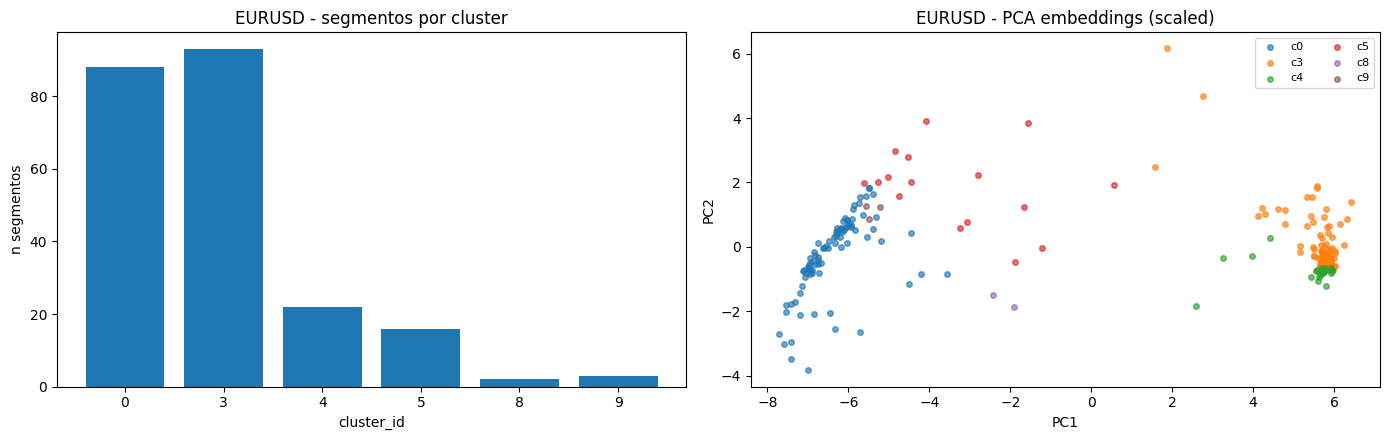

In [15]:
# =========================
# 11) Diagnosticos visuales
# =========================
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# a) conteo por cluster target
cnt = TAR_ASS['cluster_id'].value_counts().sort_index()
axes[0].bar(cnt.index.astype(str), cnt.values)
axes[0].set_title(f'{SYMBOL_TARGET} - segmentos por cluster')
axes[0].set_xlabel('cluster_id')
axes[0].set_ylabel('n segmentos')

# b) PCA de embeddings target coloreado por cluster
pca = PCA(n_components=2, random_state=SEED)
xy = pca.fit_transform(Z_TAR_ALL)
for cid in sorted(np.unique(cluster_tar)):
    m = cluster_tar == cid
    axes[1].scatter(xy[m, 0], xy[m, 1], s=16, alpha=0.65, label=f'c{cid}')
axes[1].set_title(f'{SYMBOL_TARGET} - PCA embeddings (scaled)')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()


In [16]:
# =========================
# 12) Export npz embeddings target
# =========================
np.savez_compressed(
    EMB_NPZ,
    Z_target=Z_TAR,
    Z_target_scaled=Z_TAR_ALL,
    global_segment_id=DF_TAR['global_segment_id'].to_numpy(dtype='U64'),
    cluster_id=cluster_tar.astype(np.int32),
)
print('saved embeddings npz =', EMB_NPZ)


saved embeddings npz = ./phases/phase04_transfer_clustering/output_transfer_EURUSD/EURUSD_embeddings_transfer.npz


## Resultado esperado de Phase 4

Con esto ya tienes una fase de **transferencia multi-divisa**:

- Segmentos nuevos en otra divisa (`EURUSD`) detectados automaticamente.
- Embeddings generados con encoder de atencion entrenado en referencia (`USDJPY`).
- Asignacion de clusters para esos segmentos.
- Seleccion automatica de segmentos informativos basada en perfil economico de clusters referencia.

Siguiente paso natural: backtest de reglas por cluster en la divisa target.
